In [ ]:
# !uv add arviz
# !uv add pymc
# !uv add netCDF4

In [1]:
import sys
sys.path.insert(1, '/workspaces/aml-working-paper/aml_working_paper/data')

In [2]:
import pandas as pd
import numpy as np

import pymc as pm
import arviz as az
from preprocess import preprocess_data
from bayes_hmm import build_hmm_model
from labelswitch import relabel_posterior_states

In [3]:
df_aml = pd.read_csv("/workspaces/aml-working-paper/aml_working_paper/data/synthetic_df_aml.csv")

In [4]:
train_df, val_df, test_df, train_sequences, val_sequences, test_sequences, scaler = preprocess_data(df_aml)

In [5]:
train_array = np.stack(train_sequences)
print(train_array.shape)

(70, 100, 3)


In [6]:
model = build_hmm_model(train_sequences)

print(model.compile_logp())

In [7]:
model

            pi ~ Dirichlet(<constant>)
             A ~ Dirichlet(<constant>)
            mu ~ Normal(0, 2)
         sigma ~ HalfNormal(0, 1)
hmm_likelihood ~ Potential(f(sigma, mu, A, pi))

In [8]:
with model:
    initial_point = model.initial_point()
    logp_fn = model.compile_logp()

print(logp_fn(initial_point))

-29824.76640050005


In [9]:
with model:
    trace_test = pm.sample(
        draws=5,
        tune=5,
        chains=4,
        cores=4,
        target_accept=0.9,
        random_seed=42,
    )

Only 5 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [pi, A, mu, sigma]


Output()

Sampling 4 chains for 5 tune and 5 draw iterations (20 + 20 draws total) took 1 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.
The number of samples is too small to check convergence reliably.


In [ ]:
with model:
    trace_test = pm.sample(
        draws=100,
        tune=100,
        chains=4,
        cores=4,
        target_accept=0.9,
        random_seed=42,
    )

In [ ]:
print(
    az.summary(
        trace_test,
        var_names=["pi", "A", "mu", "sigma"],
        round_to=3,
    )
)

In [ ]:
print(
    "\nDivergences:",
    trace_test.sample_stats["diverging"].sum().item()
)

In [ ]:
print(
    "\nBFMI:",
    az.bfmi(trace_test)
)

In [ ]:
az.plot_dist(
    trace_test,
    var_names=["mu"],
)

In [ ]:
aligned_trace, permutations = relabel_posterior_states(
    trace_test
)

In [ ]:
import arviz as az

summary_aligned = az.summary(
    aligned_trace,
    var_names=["pi", "A", "mu", "sigma"],
    round_to=3,
)

print(summary_aligned)

In [ ]:
az.plot_trace(
    aligned_trace,
    var_names=["mu"],
);

In [ ]:
for chain in range(permutations.shape[0]):
    unique, counts = np.unique(
        permutations[chain],
        axis=0,
        return_counts=True,
    )

    print(f"\nChain {chain}")

    for perm, count in zip(unique, counts):
        print(
            perm,
            f"{count}/{permutations.shape[1]}"
        )

In [10]:
with model:
    trace_test = pm.sample(
        draws=500,
        tune=500,
        chains=4,
        cores=4,
        target_accept=0.9,
        random_seed=42,
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [pi, A, mu, sigma]


Output()

Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 359 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [11]:
aligned_trace, permutations = relabel_posterior_states(
    trace_test
)

In [34]:
aligned_trace.to_netcdf("/workspaces/aml-working-paper/aml_working_paper/results/bayesian_hmm_aligned_trace.nc")

In [12]:
import arviz as az

summary_aligned = az.summary(
    aligned_trace,
    var_names=["pi", "A", "mu", "sigma"],
    round_to=3,
)

print(summary_aligned)

              mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
pi[0]        0.041  0.023     0.012     0.084  1967.130  1286.358  1.002   
pi[1]        0.783  0.058     0.686     0.873  2391.837  1191.559  1.001   
pi[2]        0.175  0.055     0.092     0.267  2266.545  1156.284  1.001   
A[0, 0]      0.821  0.010     0.804     0.837  2752.575  1526.705  1.002   
A[0, 1]      0.025  0.004     0.018     0.032  2107.397  1628.796  1.006   
A[0, 2]      0.154  0.010     0.138     0.170  2879.147  1659.694  1.002   
A[1, 0]      0.012  0.003     0.008     0.017  2169.311  1457.500  1.002   
A[1, 1]      0.873  0.007     0.862     0.885  2004.963  1555.001  1.006   
A[1, 2]      0.115  0.007     0.103     0.126  1865.805  1491.629  1.003   
A[2, 0]      0.161  0.010     0.146     0.177  2758.849  1611.506  1.004   
A[2, 1]      0.155  0.010     0.138     0.171  3325.388  1590.437  1.005   
A[2, 2]      0.684  0.013     0.663     0.704  2263.211  1600.886  1.001   
mu[0, 0]    

In [18]:
import matplotlib.pyplot as plt

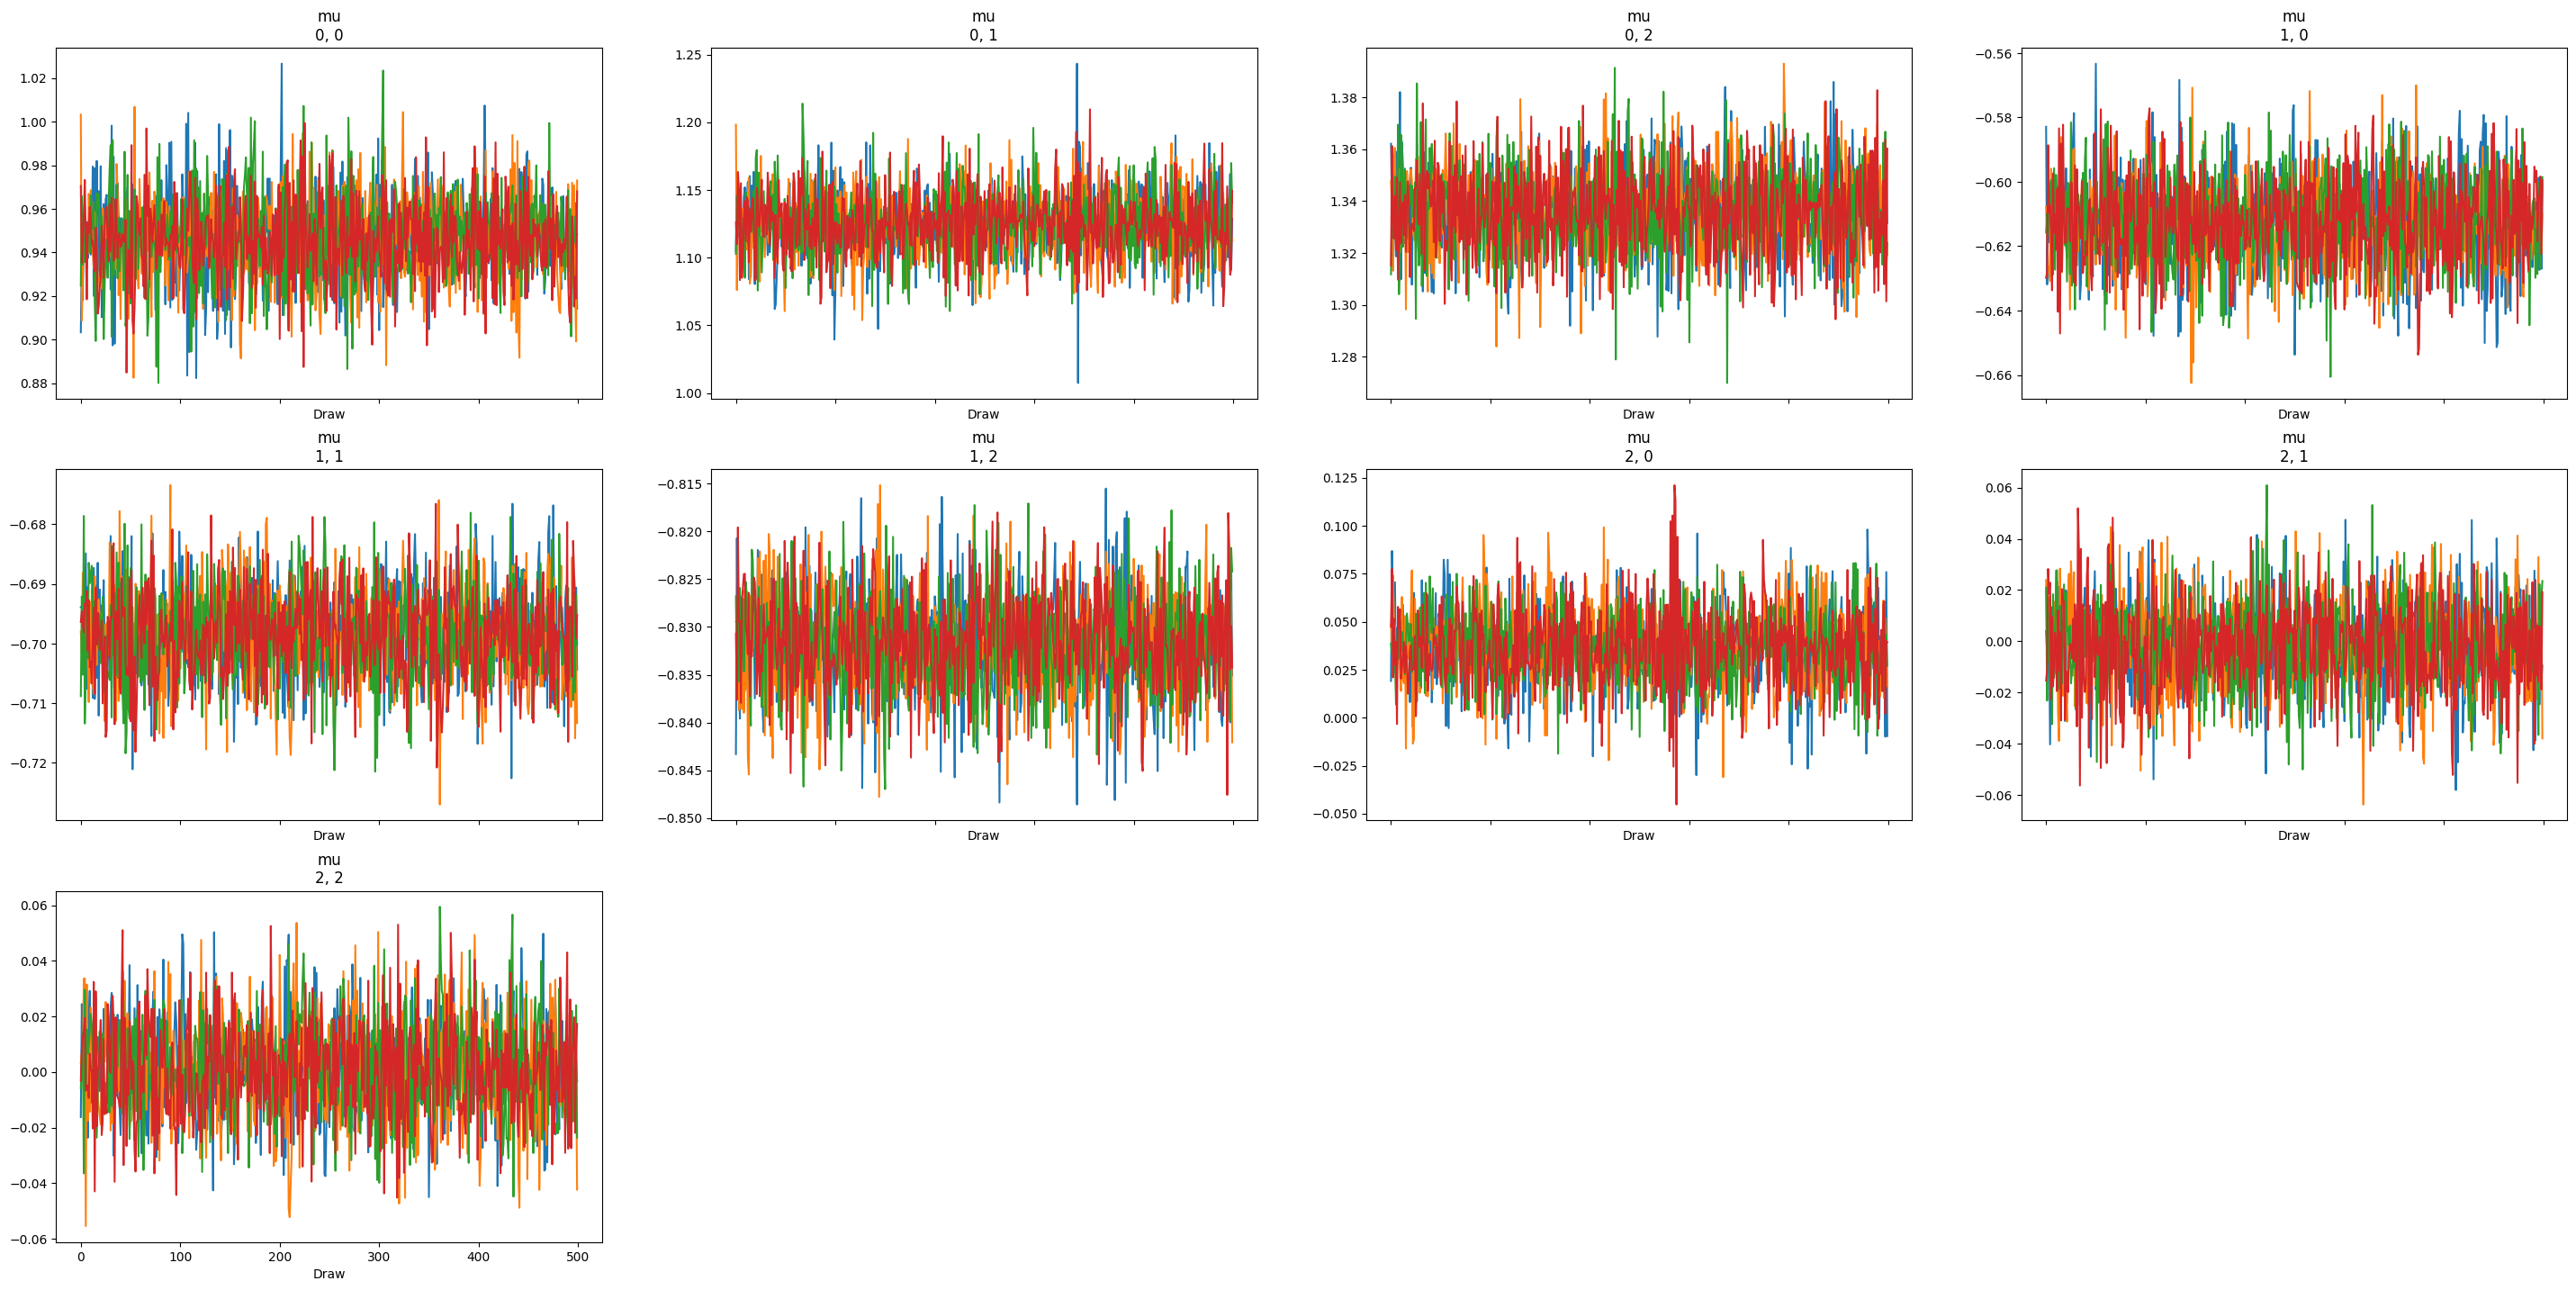

In [27]:
plt.rcParams["figure.figsize"] = (15, 15)
az.plot_trace(aligned_trace, var_names=["mu"])


In [14]:
for chain in range(permutations.shape[0]):
    unique, counts = np.unique(
        permutations[chain],
        axis=0,
        return_counts=True,
    )

    print(f"\nChain {chain}")

    for perm, count in zip(unique, counts):
        print(
            perm,
            f"{count}/{permutations.shape[1]}"
        )


Chain 0
[0 1 2] 500/500

Chain 1
[1 2 0] 500/500

Chain 2
[2 0 1] 500/500

Chain 3
[0 2 1] 500/500


In [28]:
print(
    "\nDivergences:",
    trace_test.sample_stats["diverging"].sum().item()
)


Divergences: 0


In [29]:
print(
    "\nBFMI:",
    az.bfmi(trace_test)
)


BFMI: <xarray.DataTree 'sample_stats'>
Group: /sample_stats
    Dimensions:  (chain: 4)
    Coordinates:
      * chain    (chain) int64 32B 0 1 2 3
    Data variables:
        energy   (chain) float64 32B 0.9984 0.9328 1.008 1.129
